<a href="https://colab.research.google.com/github/klissiadev/PP2.1_Perceptron/blob/main/PP21_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
import numpy as np
import random
import math
import matplotlib.pyplot as plt
from pathlib import Path
from prettytable import PrettyTable
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score)

In [7]:
# Matrículas
mat1 = "2415310025" #Ana Klissia Futado Martins
mat2 = "2415310021" #Nathalia Nobrega Silva

# Calculo do identificador
digito1 = int(mat1[-1])
digito2 = int(mat2[-1])

identificador = (digito1 + digito2) % 4
print(f"Identificador: {identificador}")

Identificador: 2


In [8]:
# Arquivos de dados
arquivoParte1 = "dataAll20262.txt"
arquivoParte2 = f"data{identificador}20262.txt"
arquivoParte3 = "dataHoldout20262.txt"

diretorio = Path(".")

arquivos = [
  arquivoParte1,
  arquivoParte2,
  arquivoParte3
]

for nome in arquivos:
  caminho = diretorio / nome
  if caminho.exists():
    print(f"Arquivo encontrado: {nome}")
  else:
    print(f"Arquivo não encontrado: {nome}")

Arquivo encontrado: dataAll20262.txt
Arquivo encontrado: data220262.txt
Arquivo encontrado: dataHoldout20262.txt


# Parte I

In [9]:
# Parâmetros iniciais da parte I
TAXA_APRENDIZADO = 0.1
LIMIAR = 0
INTERVALO_PESOS = (-0.5, 0.5)

# Cores das classes
COR_CLASSE_0 = "red"
COR_CLASSE_1 = "blue"

In [10]:
def carregarDados(arquivo):
  dados = np.load(arquivo)
  dados = np.asarray(dados, dtype=float)

  # Valida se cada exemplo contém x1, x2 e yd
  dados = dados.reshape(-1, 3)
  if not np.all(np.isfinite(dados)):
    raise ValueError("O arquivo contém valores inválidos.")

  rotulos = np.unique(dados[:, 2])
  if not np.all(np.isin(rotulos, [0, 1])):
    raise ValueError(f"Rótulos inesperados: {rotulos}")

  return dados


dados = carregarDados(arquivoParte1)

X = dados[:, :2] # coordenadas x1 e x2
y = dados[:, 2].astype(int) # classes desejadas

print("Formato dos dados:", dados.shape)
print("Quantidade de exemplos:", len(dados))
print("Classes encontradas:", np.unique(y))
print(dados[:3])

Formato dos dados: (1000, 3)
Quantidade de exemplos: 1000
Classes encontradas: [0 1]
[[ 547.91209711 -122.2431205     1.        ]
 [ 717.19583982  394.73605812    0.        ]
 [-811.64530422  951.24470327    0.        ]]


In [11]:
def treinarPerceptron(
  X,
  y,
  taxaAprendizado=0.1,
  intervaloPesos=(-0.5, 0.5),
  maxEpocas=100000
):
  # Coluna do bias
  Xbias = np.column_stack((X, np.ones(X.shape[0])))

  # Sorteio dos pesos iniciais com distribuição uniforme
  pesos = np.random.uniform(
    intervaloPesos[0],
    intervaloPesos[1],
    size=Xbias.shape[1]
  )

  pesosIniciais = pesos.copy()
  totalAjustes = 0

  for epoca in range(1, maxEpocas + 1):
    errosEpoca = 0

    for i in range(len(Xbias)):
      entrada = Xbias[i]
      saidaDesejada = y[i]

      # Potencial de ativação
      potencial = np.dot(pesos, entrada)
      # Função degrau com limiar zero
      saida = 1 if potencial >= 0 else 0
      # Atualiza os pesos se houver erro
      erro = saidaDesejada - saida

      if erro != 0:
        pesos += taxaAprendizado * erro * entrada
        totalAjustes += 1
        errosEpoca += 1

    # Convergiu: época inteira sem erros (dentro do laço de épocas)
    if errosEpoca == 0:
      return {
        "pesosIniciais": pesosIniciais,
        "pesosFinais": pesos,
        "ajustes": totalAjustes,
        "epocas": epoca,
        "convergiu": True
      }

  # Não convergiu dentro do limite
  return {
    "pesosIniciais": pesosIniciais,
    "pesosFinais": pesos,
    "ajustes": totalAjustes,
    "epocas": maxEpocas,
    "convergiu": False
  }

In [12]:

resultado = treinarPerceptron(
  X,
  y,
  taxaAprendizado=TAXA_APRENDIZADO,
  intervaloPesos=INTERVALO_PESOS
)

print("Pesos iniciais:", resultado["pesosIniciais"])
print("Pesos finais:", resultado["pesosFinais"])
print("Total de ajustes:", resultado["ajustes"])
print("Épocas executadas:", resultado["epocas"])
print("Convergiu:", resultado["convergiu"])

if not resultado["convergiu"]:
  print(
      "O algoritmo não convergiu dentro do limite. "
  )


Pesos iniciais: [-0.30900963  0.47452875  0.04324479]
Pesos finais: [ 8.61591429e+01 -4.25484347e+02  1.43244794e-01]
Total de ajustes: 65
Épocas executadas: 4
Convergiu: True


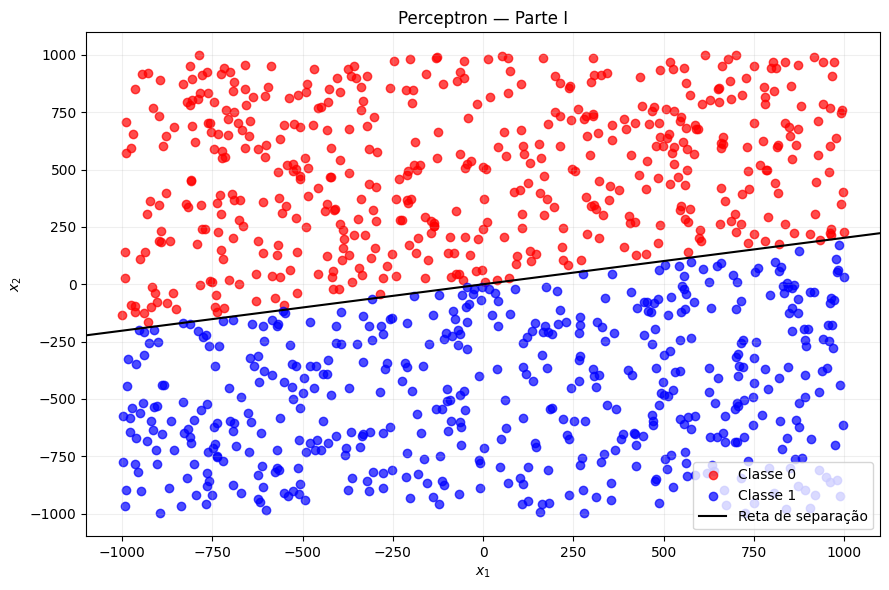

In [13]:

def plotarResultado(X, y, pesos, titulo="Perceptron — Parte I"):
  plt.figure(figsize=(9, 6))

  # Exemplos da classe 0 em vermelho
  plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    color="red",
    label="Classe 0",
    alpha=0.7
  )

  # Exemplos da classe 1 em azul
  plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    color="blue",
    label="Classe 1",
    alpha=0.7
  )

  w1, w2, bias = pesos

  xMin, xMax = X[:, 0].min(), X[:, 0].max()
  margemX = (xMax - xMin) * 0.05 or 0.5
  margemY = (X[:, 1].max() - X[:, 1].min()) * 0.05 or 0.5

  plt.xlim(xMin - margemX, xMax + margemX)
  plt.ylim(X[:, 1].min() - margemY, X[:, 1].max() + margemY)

  if abs(w2) > 1e-12:
    xReta = np.linspace(xMin - margemX, xMax + margemX, 200)
    yReta = -(w1 * xReta + bias) / w2
    plt.plot(xReta, yReta, color="black", label="Reta de separação")
  elif abs(w1) > 1e-12:
    xVertical = -bias / w1
    plt.axvline(
        x=xVertical,
        color="black",
        label="Reta de separação"
      )
  else:
    raise ValueError("A reta de separação não pode ser desenhada.")

  plt.xlabel("$x_1$")
  plt.ylabel("$x_2$")
  plt.title(titulo)
  plt.legend()
  plt.grid(alpha=0.2)
  plt.tight_layout()
  plt.show()

if resultado["convergiu"]:
  plotarResultado(X, y, resultado["pesosFinais"])

# Parte II

In [14]:
# Carregando dados do arquivo da parte 2:

dadosParte2 = carregarDados(arquivoParte2)
X2 = dadosParte2[:, :2]
X2n = X2 / 1000   # divide os atributos pela escala máxima (~1000)
# JUSTIFICATIVA: o X2 leva +40 minutos para rodar. Por isso, para essa execução, resolvemos dividir por 1000
y2 = dadosParte2[:, 2].astype(int)

print("Arquivo:", arquivoParte2)

Arquivo: data220262.txt


In [15]:
# Execução das 10 repetições para cada η × I

# coloquei isso aqui pra poder garantir reprodutibilidade dos resultados
# e os dados da tabela se manterem os mesmos
np.random.seed(13)

taxas_aprendizado = [0.4, 0.1, 0.01]
intervalos = [(-100, +100), (-0.5, 0.5)]
num_repeticoes = 10

resultados = {}

for eta in taxas_aprendizado:
  for intervalo in intervalos:
    ajustes_treinamento = []
    epocas_treinamento = []
    for _ in range(num_repeticoes):
      resultados_treinamento = treinarPerceptron(X2n, y2, eta, intervalo)
      ajustes_treinamento.append(resultados_treinamento["ajustes"])
      epocas_treinamento.append(resultados_treinamento["epocas"])

    resultados[(eta, intervalo)] = {
        "ajustes": ajustes_treinamento,
        "epocas": epocas_treinamento,
        "media_ajustes": np.mean(ajustes_treinamento),
        "desvio_padrao_ajustes": np.std(ajustes_treinamento, ddof=1),
        "min_epocas": min(epocas_treinamento),
        "max_epocas": max(epocas_treinamento)
    }

In [16]:
# Elaboração de uma tabela para mostrar os resultados das execuções

tabela = PrettyTable()
tabela.field_names = ["Taxa de Aprendizado", "Intervalo de Pesos",
                      "Qtde Ajustes", "Min Épocas", "Max Épocas"]

for (eta, intervalo), r in resultados.items():
    tabela.add_row([
        f"η = {eta}",
        f"({intervalo[0]}, +{intervalo[1]})",
        f"{r['media_ajustes']:.2f} ± {r['desvio_padrao_ajustes']:.2f}",
        r["min_epocas"],
        r["max_epocas"],
    ])

print(tabela)

+---------------------+--------------------+--------------------+------------+------------+
| Taxa de Aprendizado | Intervalo de Pesos |    Qtde Ajustes    | Min Épocas | Max Épocas |
+---------------------+--------------------+--------------------+------------+------------+
|       η = 0.4       |    (-100, +100)    |  801.40 ± 930.77   |     4      |    930     |
|       η = 0.4       |    (-0.5, +0.5)    |  887.90 ± 353.26   |     19     |    143     |
|       η = 0.1       |    (-100, +100)    |  1268.70 ± 697.64  |     10     |    144     |
|       η = 0.1       |    (-0.5, +0.5)    |  730.20 ± 255.88   |     16     |    101     |
|       η = 0.01      |    (-100, +100)    | 11850.00 ± 3321.45 |     35     |    242     |
|       η = 0.01      |    (-0.5, +0.5)    |  669.60 ± 415.33   |     3      |    196     |
+---------------------+--------------------+--------------------+------------+------------+


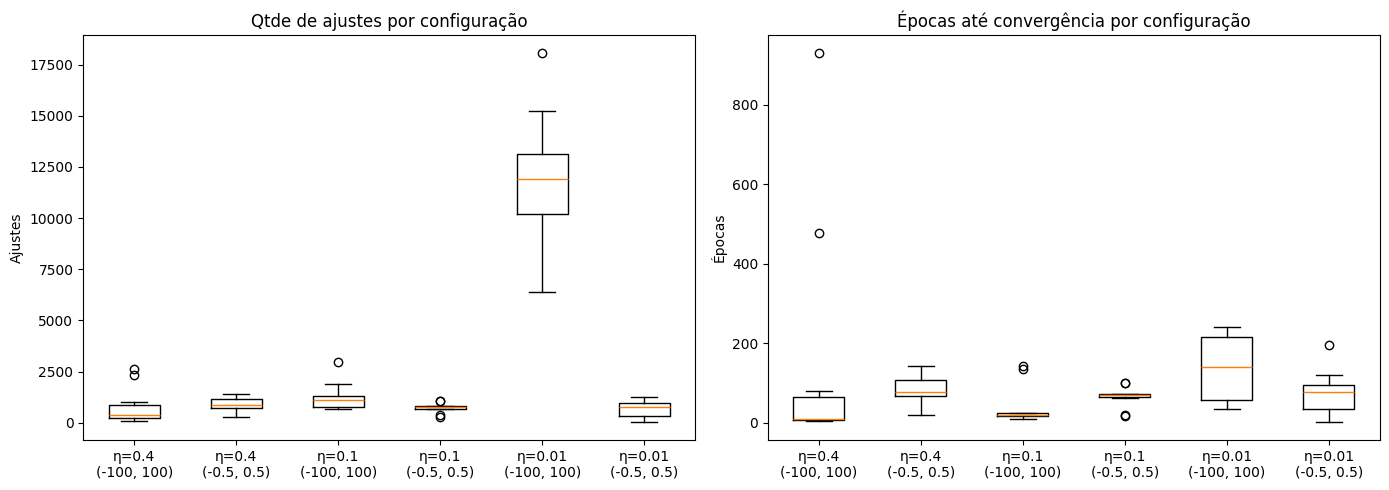

In [17]:
# Boxplot de cada experimento

rotulos = [f"η={e}\n{i}" for (e, i) in resultados.keys()]

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

axs[0].boxplot([r["ajustes"] for r in resultados.values()], tick_labels=rotulos)
axs[0].set_title("Qtde de ajustes por configuração")
axs[0].set_ylabel("Ajustes")

axs[1].boxplot([r["epocas"] for r in resultados.values()], tick_labels=rotulos)
axs[1].set_title("Épocas até convergência por configuração")
axs[1].set_ylabel("Épocas")

plt.tight_layout()
plt.show()

##  é possível afirmar acerca da existência de uma configuração melhor ou pior que as demais ou se elas são equivalentes?

Sim, existe uma configuração pior. A configuração η = 0.01      |    (-100, +100)    | 11850.00 ± 3321.45 |     35     |    242 apresentou piores resultados com esse intervalo do que as outras configurações. O boxplot pode demonstrar o tamanho da discrepância com relação às demais. A configuração também apresentou o maior valor mínimo de épocas (35).

Sobre a existência de uma configuração superior, não é possível afirmar, já que as demais configurações apresentaram médias entre 669,6 e 1.268,7 ajustes, com desvios padrão de 255,9 a 930,8 da mesma ordem das diferenças entre as médias.



# Parte III

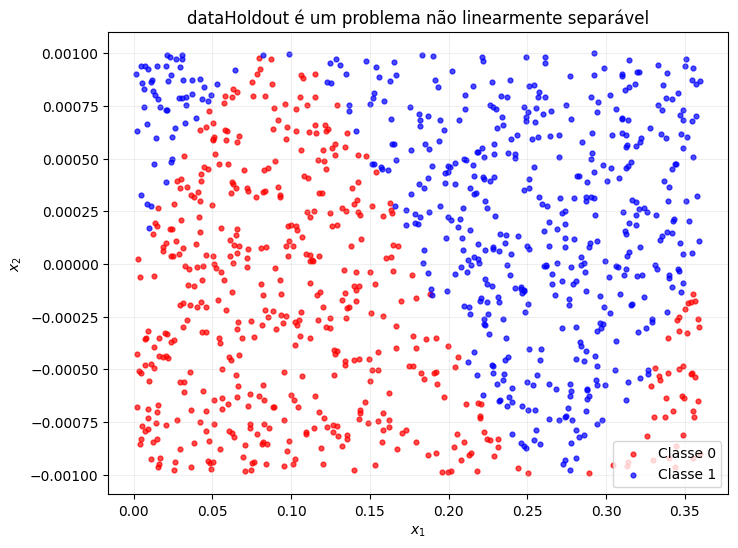

In [21]:
# apresentar um gráfico inicial que evidencie que este problema não é linearmente separável.

ESCALA = 1000   # mesma normalização precisou ser feita na Parte II

dadosHoldout = carregarDados(arquivoParte3)
XH = dadosHoldout[:, :2]
yH = dadosHoldout[:, 2].astype(int)

XHn = XH / ESCALA

plt.figure(figsize=(8, 6))
plt.scatter(XHn[yH == 0, 0], XHn[yH == 0, 1], color="red", s=12, alpha=0.7, label="Classe 0")
plt.scatter(XHn[yH == 1, 0], XHn[yH == 1, 1], color="blue", s=12, alpha=0.7, label="Classe 1")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.title("dataHoldout é um problema não linearmente separável")
plt.legend(); plt.grid(alpha=0.2); plt.show()

In [22]:
# os exemplos devem ser aleatoriamente divididos em duas partições, uma delas
# contendo 70% dos exemplos (treinamento) e outra contendo 30% (teste).
np.random.seed(identificador)

indices = np.random.permutation(len(XHn))
nTreino = int(round(0.7 * len(XHn)))
idxTreino, idxTeste = indices[:nTreino], indices[nTreino:]

XTreino, yTreino = XHn[idxTreino], yH[idxTreino]
XTeste, yTeste = XHn[idxTeste], yH[idxTeste]

print(f"Treino: {len(XTreino)} exemplos | classes: {np.bincount(yTreino)}")
print(f"Teste : {len(XTeste)} exemplos | classes: {np.bincount(yTeste)}")

Treino: 700 exemplos | classes: [349 351]
Teste : 300 exemplos | classes: [143 157]


In [23]:
def treinarPerceptronHoldout(X, y, taxaAprendizado=0.1,
                             intervaloPesos=(-0.5, 0.5), numEpocas=100):
  Xbias = np.column_stack((X, np.ones(X.shape[0])))
  pesos = np.random.uniform(intervaloPesos[0], intervaloPesos[1], size=Xbias.shape[1])
  pesosIniciais = pesos.copy()
  totalAjustes = 0
  errosPorEpoca = []

  for epoca in range(numEpocas):
    errosEpoca = 0
    for i in np.random.permutation(len(Xbias)):
      entrada = Xbias[i]
      saida = 1 if np.dot(pesos, entrada) >= 0 else 0
      erro = y[i] - saida
      if erro != 0:
        pesos += taxaAprendizado * erro * entrada
        totalAjustes += 1
        errosEpoca += 1
    errosPorEpoca.append(errosEpoca)

  return {
    "pesosIniciais": pesosIniciais,
    "pesosFinais": pesos,
    "ajustes": totalAjustes,
    "errosPorEpoca": errosPorEpoca,
  }


def prever(X, pesos):
  Xbias = np.column_stack((X, np.ones(X.shape[0])))
  return (Xbias @ pesos >= 0).astype(int)


resHoldout = treinarPerceptronHoldout(XTreino, yTreino, taxaAprendizado=0.1)
pesosH = resHoldout["pesosFinais"]

print("Pesos iniciais:", resHoldout["pesosIniciais"])
print("Pesos finais  :", pesosH)
print("Total de ajustes:", resHoldout["ajustes"])

Pesos iniciais: [ 0.08785124 -0.07246546  0.03321822]
Pesos finais  : [ 0.2833727   0.72195631 -0.06678178]
Total de ajustes: 21157


In [28]:
yPredTreino = prever(XTreino, pesosH)
yPredTeste = prever(XTeste, pesosH)
yPredTodos = prever(XHn, pesosH)

# Matriz de confusão dos testes
matriz = confusion_matrix(yTeste, yPredTeste, labels=[0, 1])
tabelaConfusao = PrettyTable()
tabelaConfusao.field_names = ["Real \\ Previsto", "Previsto 0", "Previsto 1"]
tabelaConfusao.add_row(["Real 0", f"{matriz[0, 0]} (VN)", f"{matriz[0, 1]} (FP)"])
tabelaConfusao.add_row(["Real 1", f"{matriz[1, 0]} (FN)", f"{matriz[1, 1]} (VP)"])

print("Matriz de confusão (conjunto de teste, classe positiva = 1):")
print(tabelaConfusao)

# Acurácia, precisão, revocação, F-Score
tabelaMetricas = PrettyTable()
tabelaMetricas.field_names = ["Conjunto", "Acurácia", "Precisão", "Revocação", "F-Score"]
for nome, (yReal, yPred) in {
  "Treino": (yTreino, yPredTreino),
  "Teste": (yTeste, yPredTeste),
  "Todos os dados": (yH, yPredTodos),
}.items():
  tabelaMetricas.add_row([
    nome,
    f"{accuracy_score(yReal, yPred):.4f}",
    f"{precision_score(yReal, yPred, zero_division=0):.4f}",
    f"{recall_score(yReal, yPred, zero_division=0):.4f}",
    f"{f1_score(yReal, yPred, zero_division=0):.4f}",
  ])
print(tabelaMetricas)

Matriz de confusão (conjunto de teste, classe positiva = 1):
+-----------------+------------+------------+
| Real \ Previsto | Previsto 0 | Previsto 1 |
+-----------------+------------+------------+
|      Real 0     |  125 (VN)  |  18 (FP)   |
|      Real 1     |  65 (FN)   |  92 (VP)   |
+-----------------+------------+------------+
+----------------+----------+----------+-----------+---------+
|    Conjunto    | Acurácia | Precisão | Revocação | F-Score |
+----------------+----------+----------+-----------+---------+
|     Treino     |  0.7471  |  0.8816  |   0.5726  |  0.6943 |
|     Teste      |  0.7233  |  0.8364  |   0.5860  |  0.6891 |
| Todos os dados |  0.7400  |  0.8669  |   0.5768  |  0.6927 |
+----------------+----------+----------+-----------+---------+


# Acerca da qualidade da solução perante o conjunto de testes

No conjunto de teste, o neurônio obteve acurácia de 72,33%
(217 acertos em 300 exemplos). A
reta aprendeu alguma estrutura dos dados. Ainda assim, mais de um
quarto dos exemplos de teste (83 de 300) foi classificado incorretamente.Além disso, s métricas de treino e teste são próximas (acurácia de 74,71% e 72,33%), o que indica ausência de sobreajuste relevante.

A solução generaliza de forma consistente, porém perde parte importante da classe 1.

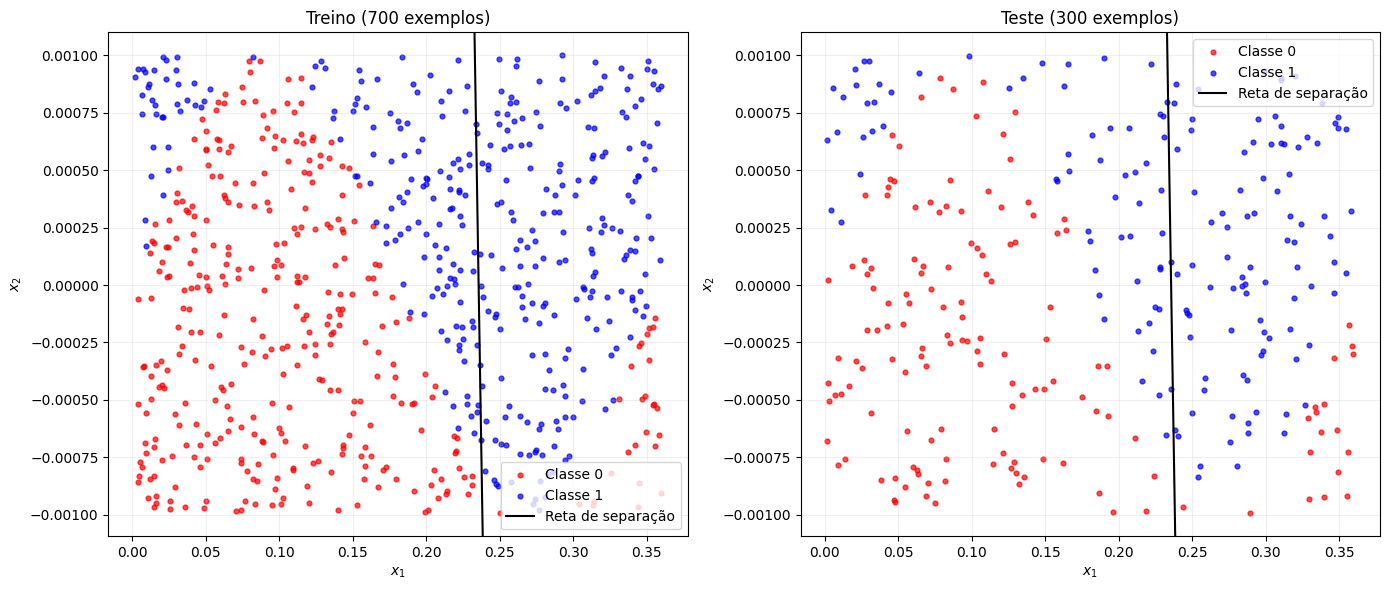

In [27]:
def desenharFronteira(ax, X, y, pesos, titulo):
  ax.scatter(X[y == 0, 0], X[y == 0, 1], color="red", s=12, alpha=0.7, label="Classe 0")
  ax.scatter(X[y == 1, 0], X[y == 1, 1], color="blue", s=12, alpha=0.7, label="Classe 1")

  w1, w2, bias = pesos
  xMin, xMax = XHn[:, 0].min(), XHn[:, 0].max()
  yMin, yMax = XHn[:, 1].min(), XHn[:, 1].max()
  margemX, margemY = (xMax - xMin) * 0.05, (yMax - yMin) * 0.05
  ax.set_xlim(xMin - margemX, xMax + margemX)
  ax.set_ylim(yMin - margemY, yMax + margemY)

  if abs(w2) > 1e-12:
    xReta = np.linspace(xMin - margemX, xMax + margemX, 200)
    ax.plot(xReta, -(w1 * xReta + bias) / w2, color="black", label="Reta de separação")
  elif abs(w1) > 1e-12:
    ax.axvline(x=-bias / w1, color="black", label="Reta de separação")

  ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
  ax.set_title(titulo); ax.legend(); ax.grid(alpha=0.2)


fig, axs = plt.subplots(1, 2, figsize=(14, 6))
desenharFronteira(axs[0], XTreino, yTreino, pesosH, f"Treino ({len(XTreino)} exemplos)")
desenharFronteira(axs[1], XTeste, yTeste, pesosH, f"Teste ({len(XTeste)} exemplos)")
plt.tight_layout(); plt.show()